<center><h1>Batra_Raghav_HW6</h1></center>

Name: Raghav Batra
<br>
Github Username: rbatra02
<br>
USC ID: 3227519293

## 1. Tree-Based Methods

Import packages

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
np.random.seed(0)

### (a) Download the APS Failure data

In [31]:
path = "../Homework 6 Data/"
train = pd.read_csv(path + "aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv(path + "aps_failure_test_set.csv", skiprows=20, na_values="na")
target = "class"
train[target] = (train[target] == "pos").astype(int)
test[target] = (test[target] == "pos").astype(int)
print(train.shape, test.shape)
train.head()

(60000, 171) (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,0,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,0,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,0,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,0,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,0,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

- **Deletion**: drop rows (listwise) or columns with too many missing values. Wastes data when lots of rows have NaNs.
- **Simple imputation**: replace with the column mean, median, or mode. Fast but shrinks variance.
- **Missing indicator**: add a 0/1 column marking that the value was missing, alongside any of the above.

I use **median imputation** since the features are very heavily skewed (median is robust to the huge outliers).

#### (ii) Calculate the coefficient of variation

In [32]:
print("train missing:", f"{train.isna().mean().mean():.2%}", "| rows with any NaN:", int(train.isna().any(axis=1).sum()))
print("test missing: ", f"{test.isna().mean().mean():.2%}", "| rows with any NaN:", int(test.isna().any(axis=1).sum()))
train.drop(columns=target).isna().mean().sort_values(ascending=False).head(10).to_frame("frac missing")

train missing: 8.28% | rows with any NaN: 59409
test missing:  8.36% | rows with any NaN: 15835


,frac missing
br_000,0.821067
bq_000,0.812033
bp_000,0.795667
bo_000,0.772217
cr_000,0.772150
ab_000,0.772150
bn_000,0.733483
bm_000,0.659150
bl_000,0.454617
bk_000,0.383900


In [33]:
train = train.fillna(train.median())
test = test.fillna(test.median())
Xtr, ytr = train.drop(columns=target), train[target]
Xte, yte = test.drop(columns=target), test[target]

full = pd.concat([train, test])
Xall = full.drop(columns=target)
cv = (Xall.std(ddof=1) / Xall.mean()).sort_values(ascending=False)
cv.to_frame("CV")

,CV
cf_000,275.595820
co_000,275.068138
ad_000,274.791073
cs_009,194.720937
dj_000,130.915233
...,...
bo_000,0.791709
bp_000,0.753230
bq_000,0.719460
br_000,0.690717


#### (iii) Plot a correlation matrix

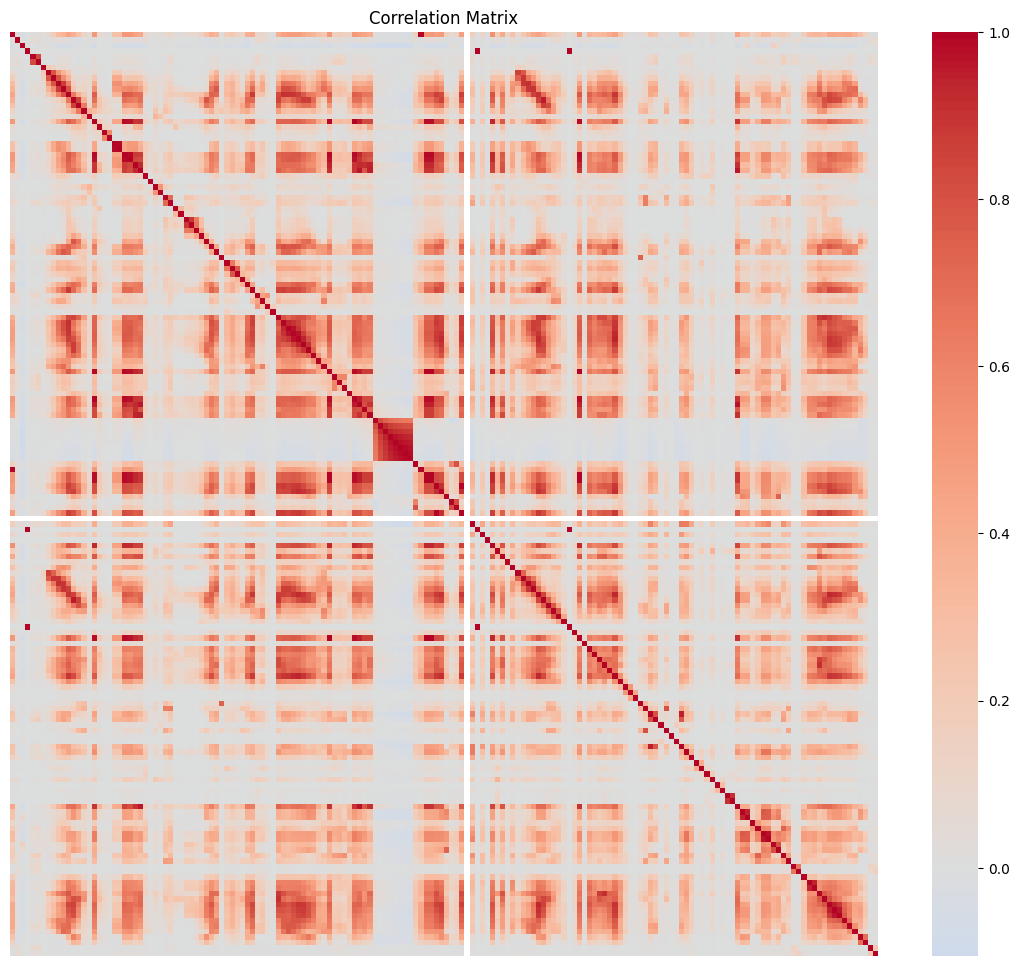

In [34]:
plt.figure(figsize=(14,12))
sns.heatmap(Xall.corr(), cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix")
plt.show()

#### (iv) Make scatter plots and box plots

13 ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dj_000', 'dh_000', 'df_000', 'as_000', 'ag_000', 'au_000', 'ak_000', 'az_009', 'ay_009']


/var/folders/zk/vwbf6t5d0fj4dl3xn399wpjw0000gn/T/ipykernel_23803/3810322283.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  full["label"] = full[target].map({0: "neg", 1: "pos"})


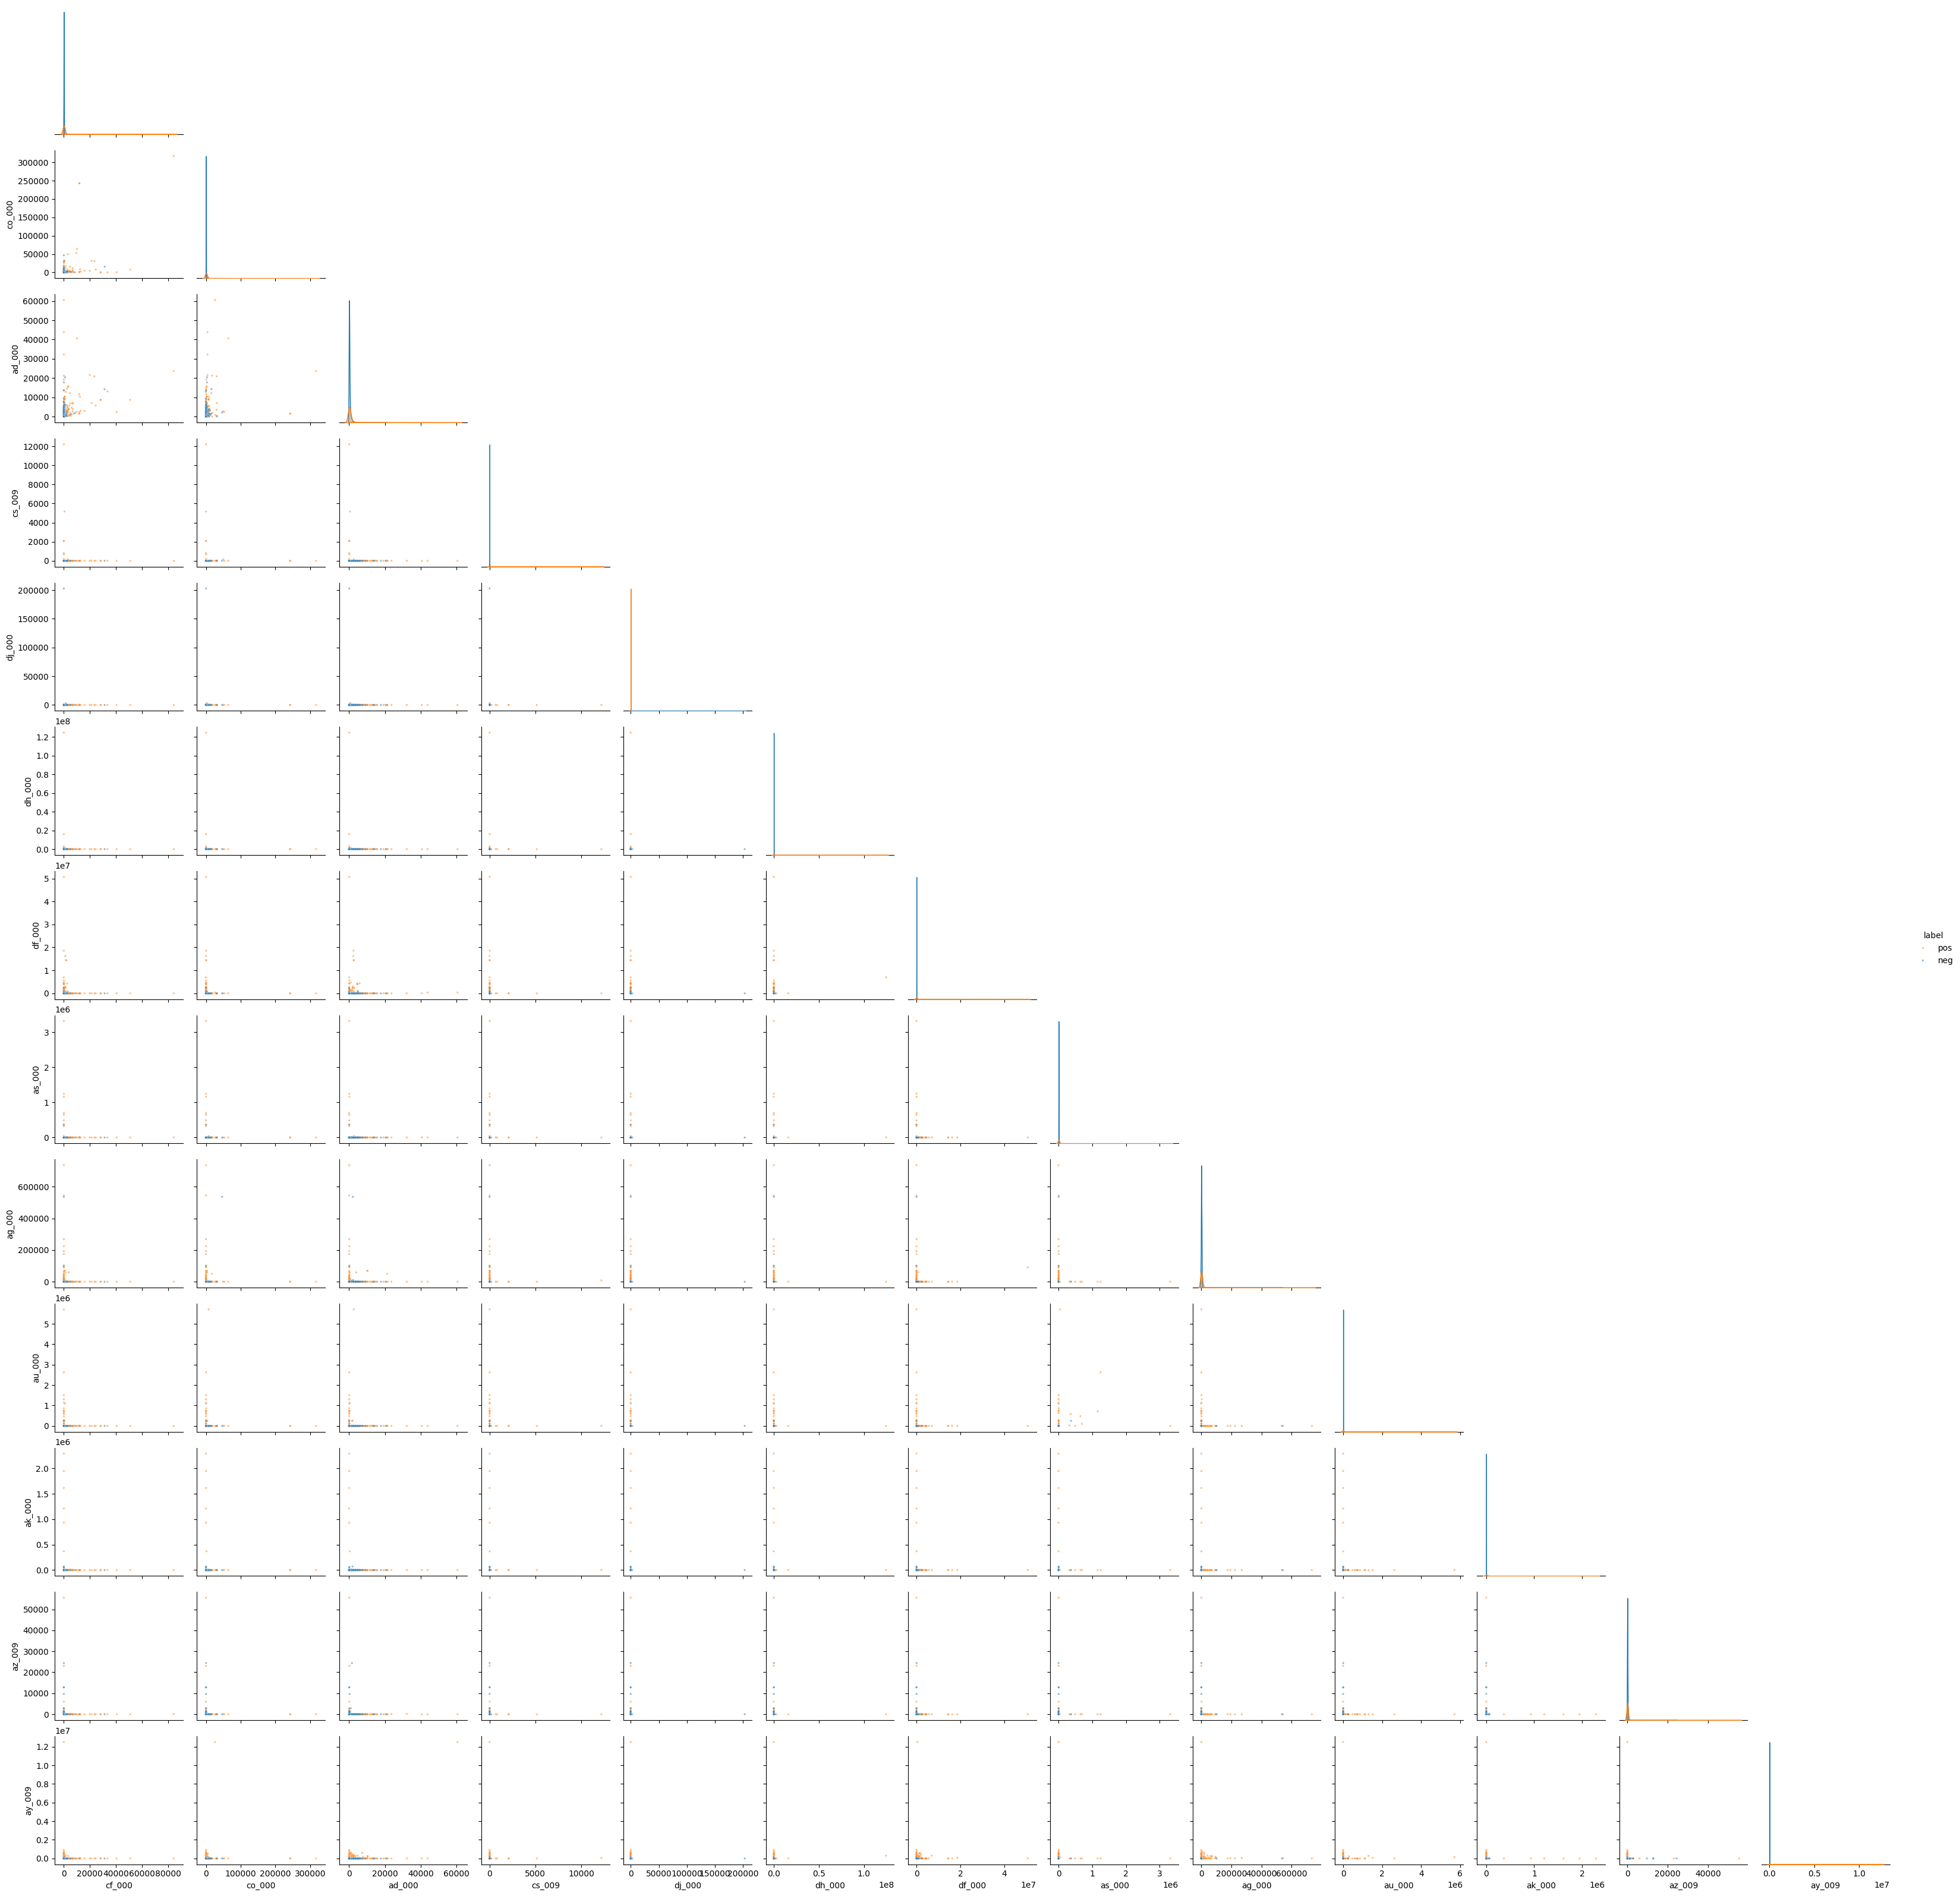

In [35]:
k = int(np.floor(np.sqrt(170)))
top = cv.index[:k].tolist()
print(k, top)

full["label"] = full[target].map({0: "neg", 1: "pos"})
samp = pd.concat([full[full[target]==1], full[full[target]==0].sample(3000, random_state=0)])
sns.pairplot(samp[top + ["label"]], hue="label", palette={"neg": "tab:blue", "pos": "tab:orange"},
             plot_kws={"s": 6, "alpha": 0.5}, corner=True)
plt.show()

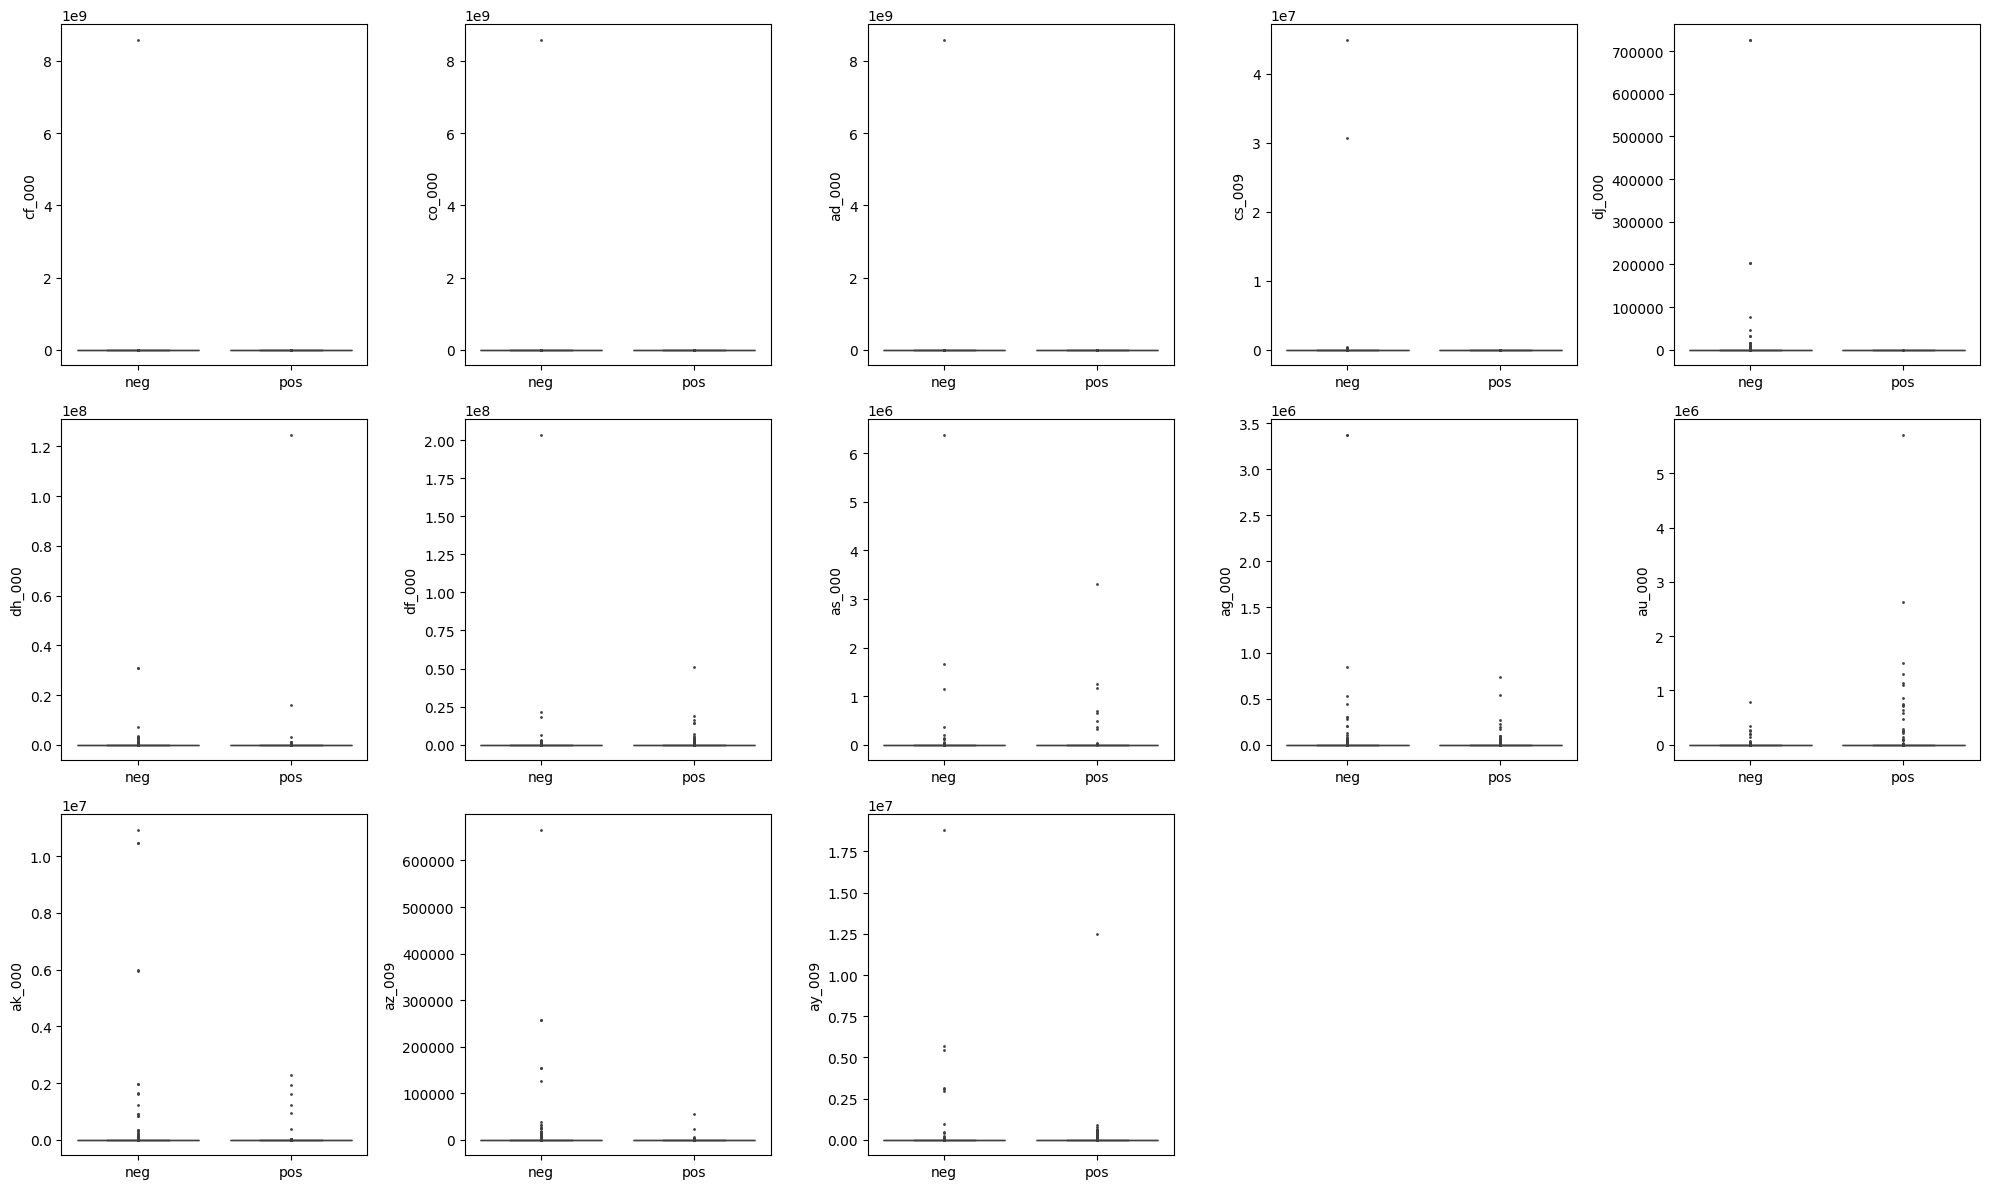

In [36]:
fig, axes = plt.subplots(3, 5, figsize=(20,12))
for ax, f in zip(axes.flat, top):
    sns.boxplot(data=full, x="label", y=f, ax=ax, hue="label",
                palette={"neg": "tab:blue", "pos": "tab:orange"}, fliersize=1)
    ax.set_xlabel(""); ax.set_ylabel(f)
for ax in axes.flat[k:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

No, you cannot conclude significance from the scatter plots alone  as the data is extremely skewed so almost all points sit at 0. 

#### (v) Is this data set imbalanced?

In [37]:
counts = pd.DataFrame({"train": ytr.value_counts(), "test": yte.value_counts()}).rename(index={0:"neg", 1:"pos"})
counts["train %"] = (counts["train"] / counts["train"].sum() * 100).round(2)
print(counts)

       train   test  train %
class                       
neg    59000  15625    98.33
pos     1000    375     1.67


Yes the data is inbalanced as 98.33% is negative class and 1.67% is positive class.

### (c) Train a random forest

Train confusion matrix:
 [[59000     0]
 [    0  1000]]
Test confusion matrix:
 [[15609    16]
 [  102   273]]
Train misclassification: 0.0000, AUC: 1.0000
Test misclassification: 0.0074, AUC: 0.9944


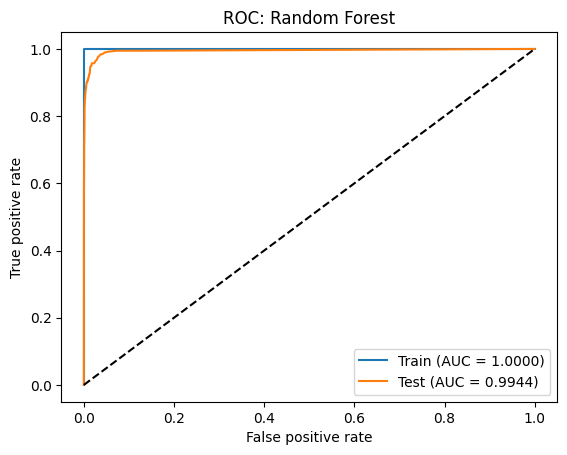

OOB error: 0.0057, Test error: 0.0074


In [38]:
rf = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)

p_tr = rf.predict_proba(Xtr)[:,1]
p_te = rf.predict_proba(Xte)[:,1]
pred_tr = rf.predict(Xtr)
pred_te = rf.predict(Xte)

print("Train confusion matrix:\n", confusion_matrix(ytr, pred_tr))
print("Test confusion matrix:\n", confusion_matrix(yte, pred_te))

err_tr = 1 - accuracy_score(ytr, pred_tr)
err_te = 1 - accuracy_score(yte, pred_te)
auc_tr = roc_auc_score(ytr, p_tr)
auc_te = roc_auc_score(yte, p_te)
print(f"Train misclassification: {err_tr:.4f}, AUC: {auc_tr:.4f}")
print(f"Test misclassification: {err_te:.4f}, AUC: {auc_te:.4f}")

fpr_tr, tpr_tr, _ = roc_curve(ytr, p_tr)
fpr_te, tpr_te, _ = roc_curve(yte, p_te)
plt.plot(fpr_tr, tpr_tr, label=f"Train (AUC = {auc_tr:.4f})")
plt.plot(fpr_te, tpr_te, label=f"Test (AUC = {auc_te:.4f})")
plt.plot([0,1], [0,1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC: Random Forest"); plt.legend()
plt.show()

oob_err = 1 - rf.oob_score_
print(f"OOB error: {oob_err:.4f}, Test error: {err_te:.4f}")

### (d) Research class imbalance in random forest

- **Class weights (cost-sensitive RF)**: weight the minority class more in the Gini impurity and in the leaf votes (`class_weight="balanced"` / `"balanced_subsample"` in sklearn).
- **Balanced random forest**: each bootstrap sample is drawn so it has equal numbers of each class (downsample the majority class per tree).
- **Resampling the data** before training: undersample the majority / oversample the minority (e.g. SMOTE).

I use `class_weight="balanced_subsample"`, with `min_samples_leaf=5`, since full depth trees pure leaves make the weights irrelevant.

Train confusion matrix:
 [[58823   177]
 [    1   999]]
Test confusion matrix:
 [[15545    80]
 [   68   307]]
Train misclassification: 0.0030, AUC: 0.9999
Test misclassification: 0.0092, AUC: 0.9955


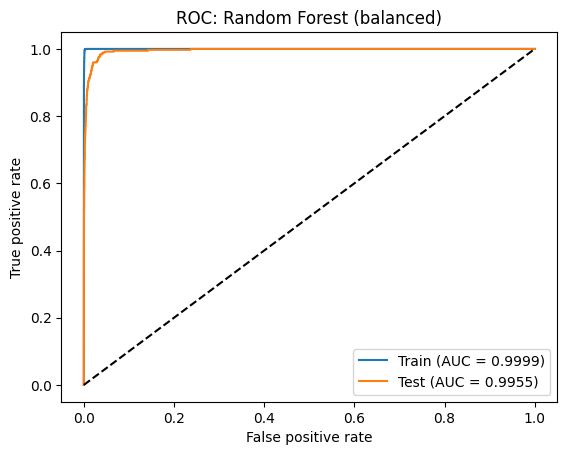

OOB error: 0.0083, Test error: 0.0092


,RF (c),RF balanced (d)
Test error,0.007375,0.009250
Test AUC,0.994442,0.995454
OOB error,0.005683,0.008267
Test FN,102.000000,68.000000
Test FP,16.000000,80.000000


In [39]:
rf_bal = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", min_samples_leaf=5,
                                oob_score=True, random_state=0, n_jobs=-1).fit(Xtr, ytr)

p_tr_b = rf_bal.predict_proba(Xtr)[:,1]
p_te_b = rf_bal.predict_proba(Xte)[:,1]
pred_tr_b = rf_bal.predict(Xtr)
pred_te_b = rf_bal.predict(Xte)

print("Train confusion matrix:\n", confusion_matrix(ytr, pred_tr_b))
print("Test confusion matrix:\n", confusion_matrix(yte, pred_te_b))

err_tr_b = 1 - accuracy_score(ytr, pred_tr_b)
err_te_b = 1 - accuracy_score(yte, pred_te_b)
auc_tr_b = roc_auc_score(ytr, p_tr_b)
auc_te_b = roc_auc_score(yte, p_te_b)
print(f"Train misclassification: {err_tr_b:.4f}, AUC: {auc_tr_b:.4f}")
print(f"Test misclassification: {err_te_b:.4f}, AUC: {auc_te_b:.4f}")

fpr_tr, tpr_tr, _ = roc_curve(ytr, p_tr_b)
fpr_te, tpr_te, _ = roc_curve(yte, p_te_b)
plt.plot(fpr_tr, tpr_tr, label=f"Train (AUC = {auc_tr_b:.4f})")
plt.plot(fpr_te, tpr_te, label=f"Test (AUC = {auc_te_b:.4f})")
plt.plot([0,1], [0,1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC: Random Forest (balanced)"); plt.legend()
plt.show()

oob_err_b = 1 - rf_bal.oob_score_
print(f"OOB error: {oob_err_b:.4f}, Test error: {err_te_b:.4f}")

# compare with (c)
cm_c, cm_d = confusion_matrix(yte, pred_te), confusion_matrix(yte, pred_te_b)
pd.DataFrame({"RF (c)": [err_te, auc_te, oob_err, cm_c[1,0], cm_c[0,1]],
              "RF balanced (d)": [err_te_b, auc_te_b, oob_err_b, cm_d[1,0], cm_d[0,1]]},
             index=["Test error", "Test AUC", "OOB error", "Test FN", "Test FP"])

Compensating for class imbalance catches more of the actual failures at the cost of more false alarms. Test error goes up from 0.0074 to 0.0093 since the test set is mostly negatives, while AUC stays about the same. OOB error is still close to the test error. The balanced forest is the better model because missing a failure is much more costly than a false alarm.

### (e) XGBoost and Model Trees

best alpha: 0
   param_reg_alpha  mean_test_auc  mean_test_acc  CV error
0             0.00       0.990171       0.994417  0.005583
1             0.01       0.990034       0.994350  0.005650
2             0.10       0.989351       0.994300  0.005700
3             1.00       0.989962       0.994367  0.005633
4            10.00       0.989268       0.993167  0.006833
5           100.00       0.982076       0.988567  0.011433
Train confusion matrix:
 [[58995     5]
 [   45   955]]
Test confusion matrix:
 [[15610    15]
 [   91   284]]
Train misclassification: 0.0008, AUC: 0.9998
Test misclassification: 0.0066, AUC: 0.9956


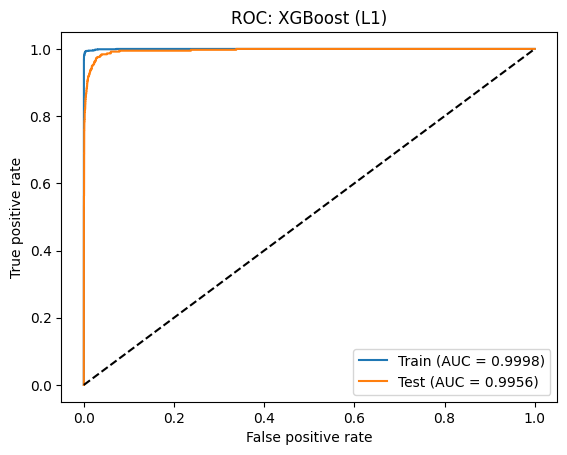

5-fold CV error: 0.0056, Test error: 0.0066


In [40]:
skf = StratifiedKFold(5, shuffle=True, random_state=0)
alphas = [0, 0.01, 0.1, 1, 10, 100]
xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, tree_method="hist",
                    eval_metric="logloss", random_state=0, n_jobs=-1)
gx = GridSearchCV(xgb, {"reg_alpha": alphas}, cv=skf, scoring={"auc": "roc_auc", "acc": "accuracy"},
                  refit="auc").fit(Xtr, ytr)

cvres = pd.DataFrame(gx.cv_results_)[["param_reg_alpha", "mean_test_auc", "mean_test_acc"]]
cvres["CV error"] = 1 - cvres["mean_test_acc"]
print("best alpha:", gx.best_params_["reg_alpha"])
print(cvres)

xgb_best = gx.best_estimator_
p_tr_x = xgb_best.predict_proba(Xtr)[:,1]
p_te_x = xgb_best.predict_proba(Xte)[:,1]
pred_tr_x = xgb_best.predict(Xtr)
pred_te_x = xgb_best.predict(Xte)

print("Train confusion matrix:\n", confusion_matrix(ytr, pred_tr_x))
print("Test confusion matrix:\n", confusion_matrix(yte, pred_te_x))

err_tr_x = 1 - accuracy_score(ytr, pred_tr_x)
err_te_x = 1 - accuracy_score(yte, pred_te_x)
auc_tr_x = roc_auc_score(ytr, p_tr_x)
auc_te_x = roc_auc_score(yte, p_te_x)
print(f"Train misclassification: {err_tr_x:.4f}, AUC: {auc_tr_x:.4f}")
print(f"Test misclassification: {err_te_x:.4f}, AUC: {auc_te_x:.4f}")

fpr_tr, tpr_tr, _ = roc_curve(ytr, p_tr_x)
fpr_te, tpr_te, _ = roc_curve(yte, p_te_x)
plt.plot(fpr_tr, tpr_tr, label=f"Train (AUC = {auc_tr_x:.4f})")
plt.plot(fpr_te, tpr_te, label=f"Test (AUC = {auc_te_x:.4f})")
plt.plot([0,1], [0,1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC: XGBoost (L1)"); plt.legend()
plt.show()

cv_err_x = 1 - gx.cv_results_["mean_test_acc"][gx.best_index_]
print(f"5-fold CV error: {cv_err_x:.4f}, Test error: {err_te_x:.4f}")

### (f) Use SMOTE to pre-process your data

best alpha: 1
   param_xgb__reg_alpha  mean_test_auc  mean_test_acc  CV error
0                  0.00       0.987856       0.990750  0.009250
1                  0.01       0.987699       0.990717  0.009283
2                  0.10       0.987174       0.990750  0.009250
3                  1.00       0.988021       0.990900  0.009100
4                 10.00       0.987225       0.989850  0.010150
5                100.00       0.984881       0.979917  0.020083
after SMOTE: {0: 59000, 1: 59000}
Train confusion matrix:
 [[58735   265]
 [   50   950]]
Test confusion matrix:
 [[15454   171]
 [   43   332]]
Train misclassification: 0.0052, AUC: 0.9989
Test misclassification: 0.0134, AUC: 0.9937


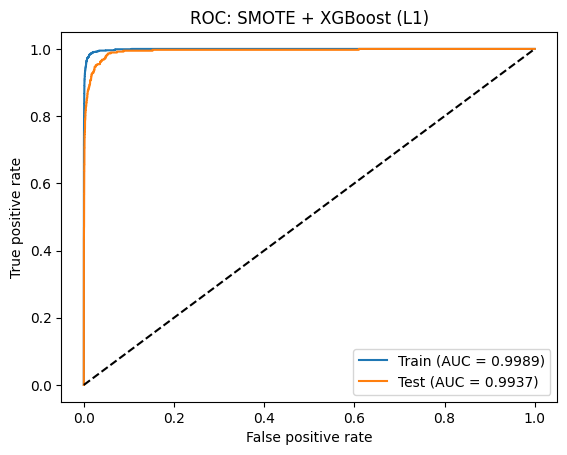

5-fold CV error: 0.0091, Test error: 0.0134


,XGB (e),SMOTE + XGB (f)
Test error,0.006625,0.013375
Test AUC,0.995595,0.993699
CV error,0.005583,0.009100
Test FN,91.000000,43.000000
Test FP,15.000000,171.000000


In [41]:
pipe = ImbPipeline([("smote", SMOTE(random_state=0)),
                    ("xgb", XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, tree_method="hist",
                                          eval_metric="logloss", random_state=0, n_jobs=-1))])
gs = GridSearchCV(pipe, {"xgb__reg_alpha": alphas}, cv=skf, scoring={"auc": "roc_auc", "acc": "accuracy"},
                  refit="auc").fit(Xtr, ytr)

cvres_s = pd.DataFrame(gs.cv_results_)[["param_xgb__reg_alpha", "mean_test_auc", "mean_test_acc"]]
cvres_s["CV error"] = 1 - cvres_s["mean_test_acc"]
print("best alpha:", gs.best_params_["xgb__reg_alpha"])
print(cvres_s)

# final model: GridSearchCV refits the pipeline on SMOTE applied to the full training set
smote_xgb = gs.best_estimator_.named_steps["xgb"]
Xsm, ysm = SMOTE(random_state=0).fit_resample(Xtr, ytr)
print("after SMOTE:", ysm.value_counts().to_dict())

p_tr_s = smote_xgb.predict_proba(Xtr)[:,1]
p_te_s = smote_xgb.predict_proba(Xte)[:,1]
pred_tr_s = smote_xgb.predict(Xtr)
pred_te_s = smote_xgb.predict(Xte)

print("Train confusion matrix:\n", confusion_matrix(ytr, pred_tr_s))
print("Test confusion matrix:\n", confusion_matrix(yte, pred_te_s))

err_tr_s = 1 - accuracy_score(ytr, pred_tr_s)
err_te_s = 1 - accuracy_score(yte, pred_te_s)
auc_tr_s = roc_auc_score(ytr, p_tr_s)
auc_te_s = roc_auc_score(yte, p_te_s)
print(f"Train misclassification: {err_tr_s:.4f}, AUC: {auc_tr_s:.4f}")
print(f"Test misclassification: {err_te_s:.4f}, AUC: {auc_te_s:.4f}")

fpr_tr, tpr_tr, _ = roc_curve(ytr, p_tr_s)
fpr_te, tpr_te, _ = roc_curve(yte, p_te_s)
plt.plot(fpr_tr, tpr_tr, label=f"Train (AUC = {auc_tr_s:.4f})")
plt.plot(fpr_te, tpr_te, label=f"Test (AUC = {auc_te_s:.4f})")
plt.plot([0,1], [0,1], "k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC: SMOTE + XGBoost (L1)"); plt.legend()
plt.show()

cv_err_s = 1 - gs.cv_results_["mean_test_acc"][gs.best_index_]
print(f"5-fold CV error: {cv_err_s:.4f}, Test error: {err_te_s:.4f}")

# compare with (e)
cm_e, cm_f = confusion_matrix(yte, pred_te_x), confusion_matrix(yte, pred_te_s)
pd.DataFrame({"XGB (e)": [err_te_x, auc_te_x, cv_err_x, cm_e[1,0], cm_e[0,1]],
              "SMOTE + XGB (f)": [err_te_s, auc_te_s, cv_err_s, cm_f[1,0], cm_f[0,1]]},
             index=["Test error", "Test AUC", "CV error", "Test FN", "Test FP"])

SMOTE more than halves the missed failures from 91 to 43. The recall goes from 76% to 89%, but adds a lot of false alarms from 15 to 171. The test error goes up from 0.0066 to 0.0134 and AUC drops slightly but still around 0.99, since accuracy is dominated by the negative class and SMOTE mostly shifts the decision boundary rather than improving the ranking. The CV error of 0.0091 is a little lower than the test error 0.0134 but still a reasonable estimate. The uncompensated model looks better by accuracy, but SMOTE is better at the actual goal of catching failures.

## 2. ISLR 6.6.3

**(a) Training RSS: (iv) steadily decrease.** At $s=0$ all $\beta_j=0$; as $s$ grows the constraint loosens so the model gets more flexible and the training RSS can only go down, until it reaches the least squares fit.

**(b) Test RSS: (ii) decrease initially, then eventually increase in a U shape.** Going from the null model to a more flexible one first reduces bias faster than variance grows, then there is overfitting which makes the test RSS go back up.

**(c) Variance: (iii) steadily increase.** more flexibility means more variance.

**(d) Squared bias: (iv) steadily decrease.** More flexibility lets the model get closer to the true relationship.

**(e) Irreducible error: (v) remain constant.** $\text{Var}(\epsilon)$ doesn't depend on the model.

## 3. ISLR 6.6.5

$n=p=2$, $x_{11}=x_{12}=x_1$, $x_{21}=x_{22}=x_2$, $y_1+y_2=0$, $x_1+x_2=0$, so $\hat\beta_0=0$.

**(a) Ridge optimization problem**
$$\min_{\beta_1,\beta_2}\; (y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(\beta_1^2+\beta_2^2)$$

**(b) Show $\hat\beta_1=\hat\beta_2$ for ridge**

Plug in $x_{i1}=x_{i2}=x_i$:
$$f(\beta_1,\beta_2) = \sum_{i=1}^2 \big(y_i-(\beta_1+\beta_2)x_i\big)^2+\lambda(\beta_1^2+\beta_2^2)$$
Set the partial derivatives to 0:
$$\frac{\partial f}{\partial\beta_1} = -2\sum_i x_i\big(y_i-(\beta_1+\beta_2)x_i\big) + 2\lambda\beta_1 = 0$$
$$\frac{\partial f}{\partial\beta_2} = -2\sum_i x_i\big(y_i-(\beta_1+\beta_2)x_i\big) + 2\lambda\beta_2 = 0$$
subtract the two above partial derivatives gives $2\lambda(\beta_1-\beta_2)=0$, and since $\lambda>0$, $\hat\beta_1=\hat\beta_2$. 

Intuition: the RSS only depends on $\beta_1+\beta_2$, and for a fixed sum, $\beta_1^2+\beta_2^2$ is smallest when they're equal.

**(c) Lasso optimization problem**
$$\min_{\beta_1,\beta_2}\; (y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(|\beta_1|+|\beta_2|)$$

**(d) Lasso coefficients are not unique**

RSS only depends on $c=\beta_1+\beta_2$. Using $x_2=-x_1$ and $y_2=-y_1$:
$$f = 2(y_1-cx_1)^2 + \lambda(|\beta_1|+|\beta_2|)$$
For a fixed $c$, $|\beta_1|+|\beta_2| \ge |\beta_1+\beta_2| = |c|$ with equality whenever $\beta_1$ and $\beta_2$ have the same sign. So the problem reduces to minimizing $2(y_1-cx_1)^2+\lambda|c|$ over $c$, which gives some optimal $\hat c$, and **every** pair with
$$\hat\beta_1+\hat\beta_2=\hat c,\quad \hat\beta_1\hat\beta_2\ge 0$$
is a solution. That's a whole line segment (from $(\hat c,0)$ to $(0,\hat c)$), so the solution isn't unique.

Geometrically: in the constraint form $|\beta_1|+|\beta_2|\le s$, the RSS contours are lines $\beta_1+\beta_2=\text{const}$, which are parallel to the edge of the diamond $\beta_1+\beta_2=s$ (or $=-s$). So the contour touches the diamond along an entire edge instead of at a single point.

## 4. ISLR 8.4.5

In [42]:
probs = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
votes_red = (probs > 0.5).sum()
print(f"Majority vote: {votes_red} of 10 say Red: {'Red' if votes_red > 5 else 'Green'}")
print(f"Average probability: {probs.mean():.2f}: {'Red' if probs.mean() > 0.5 else 'Green'}")

Majority vote: 6 of 10 say Red: Red
Average probability: 0.45: Green


## 5. ISLR 9.7.3

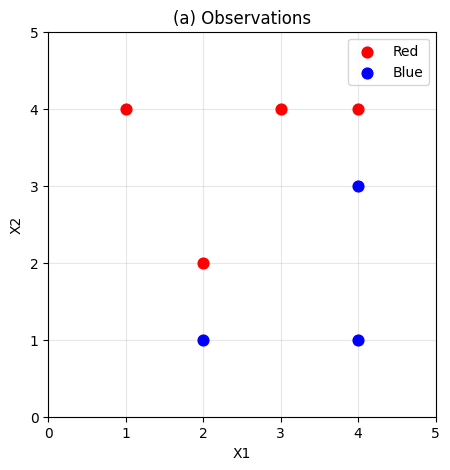

In [43]:
pts = pd.DataFrame({"X1": [3,2,4,1,2,4,4], "X2": [4,2,4,4,1,3,1],
                    "Y": ["Red","Red","Red","Red","Blue","Blue","Blue"]})

def base_plot(title):
    fig, ax = plt.subplots(figsize=(5,5))
    for c in ["Red", "Blue"]:
        d = pts[pts.Y == c]
        ax.scatter(d.X1, d.X2, c=c.lower(), s=60, label=c, zorder=3)
    ax.set_xlim(0,5); ax.set_ylim(0,5); ax.set_xlabel("X1"); ax.set_ylabel("X2")
    ax.set_title(title); ax.grid(alpha=.3)
    return ax

base_plot("(a) Observations"); plt.legend(); plt.show()

**(b)** Red line: $X_2=X_1$ and Blue line: $X_2=X_1-1$. The maximal margin hyperplane goes between them:
$$X_2 = X_1 - 0.5 \quad\Longleftrightarrow\quad 0.5 - X_1 + X_2 = 0$$

**(c)** Classify to **Red** if $0.5 - X_1 + X_2 > 0$, and to **Blue** otherwise. where $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

**(d)** The margin is the perpendicular distance from the hyperplane to the closest observations (the support vectors):
$$M = \frac{|\beta_0 + \beta_1 x_1 + \beta_2 x_2|}{\sqrt{\beta_1^2 + \beta_2^2}}$$
Using the support vector (2,2):
$$M = \frac{|0.5 - 2 + 2|}{\sqrt{(-1)^2 + 1^2}} = \frac{0.5}{\sqrt2} \approx 0.354$$
The margin boundaries are $X_2 = X_1$ and $X_2 = X_1 - 1$.

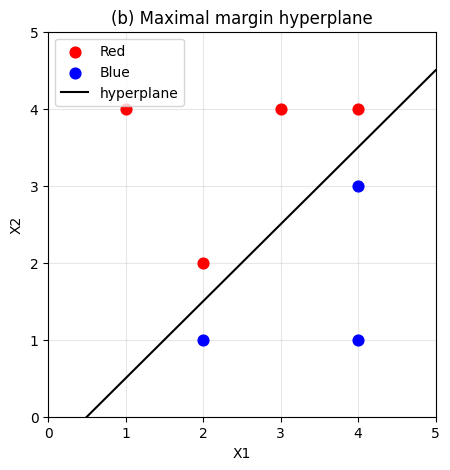

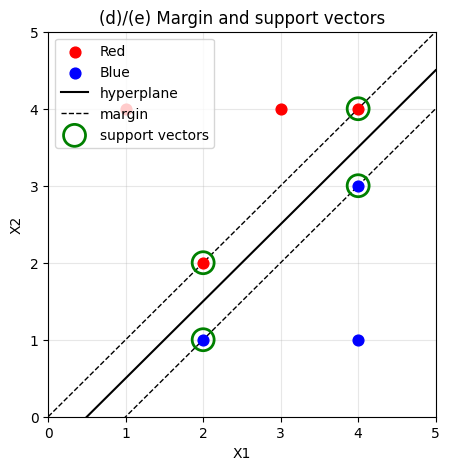

In [44]:
xs = np.linspace(0, 5, 100)
ax = base_plot("(b) Maximal margin hyperplane")
ax.plot(xs, xs - 0.5, "k-", label="hyperplane")
plt.legend(); plt.show()
sv = pts.iloc[[1,2,4,5]]
ax = base_plot("(d)/(e) Margin and support vectors")
ax.plot(xs, xs - 0.5, "k-", label="hyperplane")
ax.plot(xs, xs, "k--", lw=1, label="margin")
ax.plot(xs, xs - 1, "k--", lw=1)
ax.scatter(sv.X1, sv.X2, s=250, facecolors="none", edgecolors="green", lw=2, label="support vectors", zorder=4)
plt.legend(); plt.show()

**(e)** Support vectors: **(2,2), (4,4)** (Red) and **(2,1), (4,3)** (Blue).

**(f)** The 7th observation (4,1) is Blue and far from the margin (it's not a support vector). The maximal margin hyperplane only depends on the support vectors, so moving (4,1) slightly won't change the hyperplane.

**(g)** $0.3 - X_1 + X_2 = 0$ (i.e. $X_2 = X_1 - 0.3$). It still separates the classes but it's closer to the Red points, so the margin is smaller.

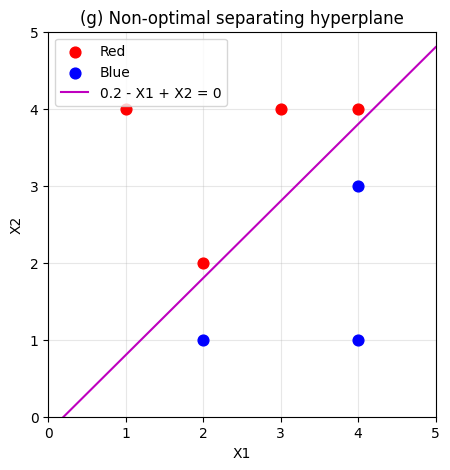

In [45]:
ax = base_plot("(g) Non-optimal separating hyperplane")
ax.plot(xs, xs - 0.2, "m-", label="0.2 - X1 + X2 = 0")
plt.legend(); plt.show()

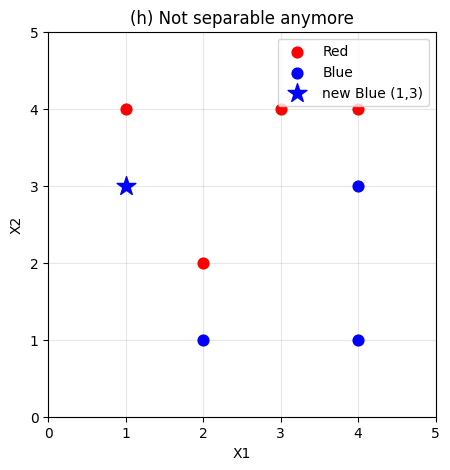

In [46]:
ax = base_plot("(h) Not separable anymore")
ax.scatter([1], [3], c="blue", marker="*", s=200, label="new Blue (1,3)", zorder=4)
plt.legend(); plt.show()